# Analysis 3: Which categories get the most engagement per view?

**Business question.** For the same number of views, which categories get more likes and comments, and how do countries compare? Likes and comments signal an engaged audience, which matters to advertisers and to the recommendation system.

**Metric.** Likes per 1,000 views and comments per 1,000 views, measured on each video's first trending day. Videos with ratings or comments turned off are left out of that measure (they are missing, not zero), and so are videos that hide their view count. Videos already trending on the first day of the data are left out because their age is unknown.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

from streampulse.analysis import (
    DATA_START, INDIA_LIST_CHANGE, load_first_day_engagement, median_with_ci, percent_differences,
)
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, SINGLE_SERIES_COLOR, apply_chart_style
from streampulse.database import connect

apply_chart_style()
connection = connect()
engagement = load_first_day_engagement(connection)

engagement.groupby("country").agg(
    videos=("video_id", "size"),
    with_likes=("likes_per_1k_views", "count"),
    with_comments=("comments_per_1k_views", "count"),
).loc[COUNTRIES]

,videos,with_likes,with_comments
country,,,
IN,78673,77919,78193
US,46923,46654,46324
GB,47391,47121,46505


## 1. Why the first trending day

An earlier version of this analysis (SQL query 6 and the EDA notebook) measured engagement on the day a video had its most views, which is usually its last day on the list. Engagement per view falls as a video ages, because the first viewers are the most committed fans. US and UK videos stay on the list about twice as long as Indian ones, so a last-day measure compares US and UK videos at an older age than Indian videos.

In [2]:
peak_day = connection.execute(f"""
    SELECT country,
           median(1000.0 * likes_at_peak / peak_views) AS likes_per_1k_on_peak_day,
           avg(days_trending) AS mean_days_on_list
    FROM trending_videos
    WHERE peak_views > 0 AND first_trending_date > DATE '{DATA_START}'
    GROUP BY country
""").df().set_index("country")

peak_day.assign(
    likes_per_1k_on_first_day=engagement.groupby("country")["likes_per_1k_views"].median()
).loc[COUNTRIES, ["likes_per_1k_on_first_day", "likes_per_1k_on_peak_day", "mean_days_on_list"]].round(1)

,likes_per_1k_on_first_day,likes_per_1k_on_peak_day,mean_days_on_list
country,,,
IN,45.5,36.4,3.1
US,54.6,42.5,5.6
GB,50.5,39.4,5.6


## 2. A break in India's data on 6 October 2022

Weekly median likes per 1,000 views shows a sudden drop for India. On 6 October 2022 India's daily list stopped holding a steady 200 videos, and the daily median fell from about 60 to about 42 likes per 1,000 views that same day, in every category. Audience behaviour does not change overnight, so this is most likely a change in how YouTube built India's list or how the dataset collected it. The data does not say which. From here on India is treated as two periods. India's level was not flat before the break either: it rose from about 45 in 2020 to about 70 in mid-2022.

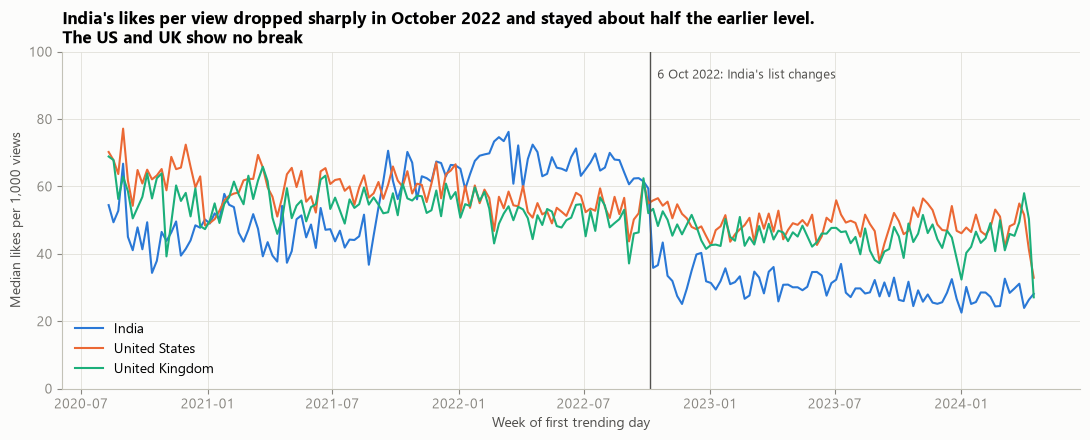

,likes_per_1k_views,comments_per_1k_views
country_period,,
GB,50.45,3.36
IN before Oct 2022,58.12,1.63
IN from Oct 2022,29.96,1.37
US,54.59,3.71


In [3]:
weekly_likes = (
    engagement.assign(week=engagement["first_trending_date"].dt.to_period("W").dt.start_time)
    .groupby(["week", "country"])["likes_per_1k_views"].median()
    .unstack("country")[COUNTRIES]
)

fig, ax = plt.subplots(figsize=(11, 4.5))
for country in COUNTRIES:
    ax.plot(weekly_likes.index, weekly_likes[country], color=COUNTRY_COLORS[country], linewidth=1.5,
            label=COUNTRY_NAMES[country])
list_change_x = mdates.date2num(pd.Timestamp(INDIA_LIST_CHANGE).to_pydatetime())
ax.axvline(list_change_x, color="#52514e", linewidth=1)
ax.text(list_change_x + 10, 92, "6 Oct 2022: India's list changes", fontsize=9, color="#52514e")
ax.set_ylim(0, 100)
ax.set_ylabel("Median likes per 1,000 views")
ax.set_xlabel("Week of first trending day")
ax.set_title("India's likes per view dropped sharply in October 2022 and stayed about half the earlier level.\n"
             "The US and UK show no break")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

engagement.groupby("country_period")[["likes_per_1k_views", "comments_per_1k_views"]].median().round(2)

Does the break change the results of analyses 1 and 2? India's time to trend and time on the list are the same before and after it, so those findings hold in both periods.

In [4]:
connection.execute(f"""
    SELECT
        country,
        CASE WHEN first_trending_date < DATE '{INDIA_LIST_CHANGE}' THEN 'before' ELSE 'from' END AS oct_2022,
        count(*) AS videos,
        round(avg(days_trending), 2) AS mean_days_on_list,
        round(100 * avg(CAST(date_diff('day', CAST(published_at AS DATE), first_trending_date) <= 1 AS INTEGER)), 1)
            AS pct_trended_by_next_day
    FROM trending_videos
    WHERE first_trending_date > DATE '{DATA_START}' AND last_trending_date < DATE '2024-04-15'
    GROUP BY ALL
    ORDER BY country, oct_2022
""").df()

,country,oct_2022,videos,mean_days_on_list,pct_trended_by_next_day
0,GB,before,28824,5.34,63.5
1,GB,from,18383,5.92,47.3
2,IN,before,45791,3.24,86.9
3,IN,from,32696,3.03,87.9
4,US,before,28899,5.31,60.2
5,US,from,17843,6.14,52.8


## 3. Engagement by category and country

Medians with 95% distribution-free confidence intervals, for categories with at least 200 videos in a country.

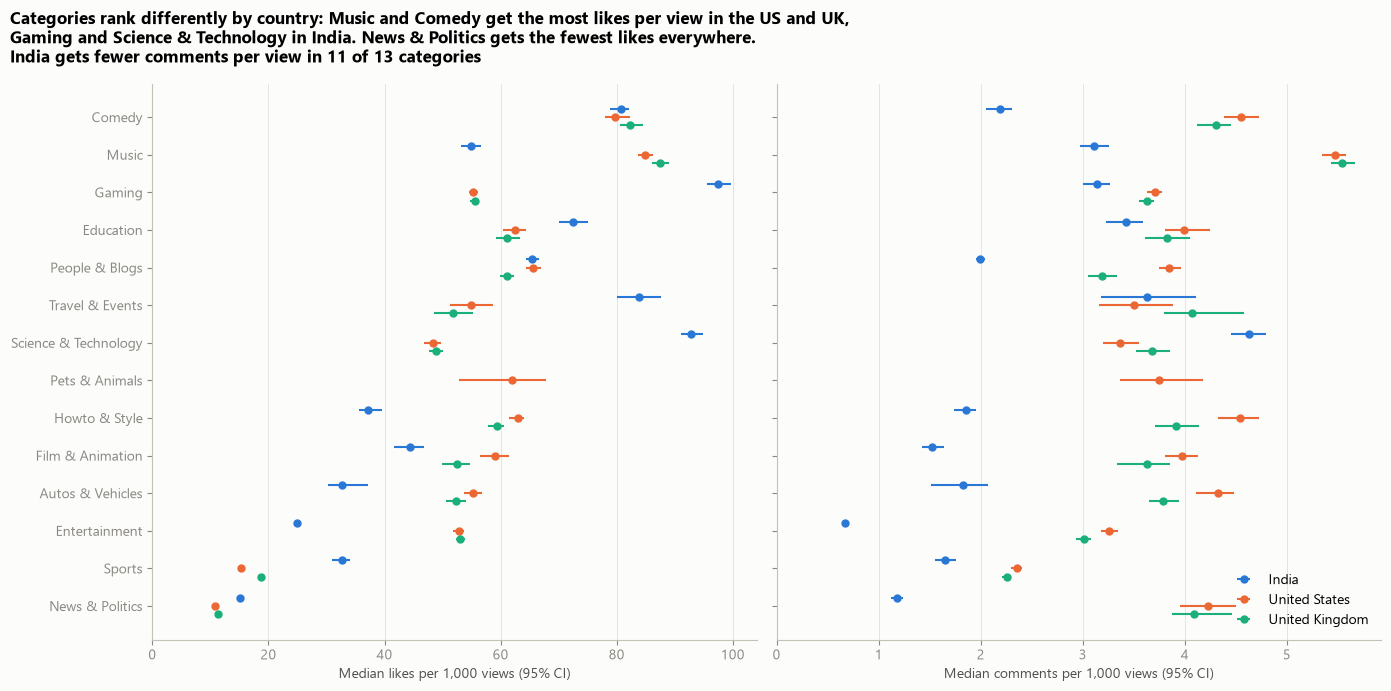

Likes per 1,000 views              \
country                                 IN    US    GB   
category                                                 
Comedy                                80.7  79.7  82.4   
Music                                 54.9  84.8  87.4   
Gaming                                97.5  55.3  55.5   
Education                             72.5  62.4  61.2   
People & Blogs                        65.5  65.5  61.1   
Travel & Events                       83.8  54.8  51.8   
Science & Technology                  92.7  48.3  48.9   
Pets & Animals                         NaN  62.0   NaN   
Howto & Style                         37.2  63.0  59.4   
Film & Animation                      44.4  59.0  52.5   
Autos & Vehicles                      32.7  55.3  52.3   
Entertainment                         24.9  52.7  53.1   
Sports                                32.6  15.3  18.7   
News & Politics                       15.1  10.7  11.4   

                     Comments per 1,000 views            
country                                    IN   US   GB  
category                                                 
Comedy                                    2.2  4.6  4.3  
Music                                     3.1  5.5  5.5  
Gaming                                    3.1  3.7  3.6  
Education                                 3.4  4.0  3.8  
People & Blogs                            2.0  3.8  3.2  
Travel & Events                           3.6  3.5  4.1  
Science & Technology                      4.6  3.4  3.7  
Pets & Animals                            NaN  3.8  NaN  
Howto & Style                             1.9  4.5  3.9  
Film & Animation                          1.5  4.0  3.6  
Autos & Vehicles                          1.8  4.3  3.8  
Entertainment                             0.7  3.3  3.0  
Sports                                    1.7  2.4  2.3  
News & Politics                           1.2  4.2  4.1

In [5]:
metric_labels = {"likes_per_1k_views": "Likes per 1,000 views", "comments_per_1k_views": "Comments per 1,000 views"}
category_medians = {
    metric: engagement.groupby(["country", "category"])[metric].apply(median_with_ci).unstack()
            .query("videos >= 200").reset_index()
    for metric in metric_labels
}
category_order = (
    category_medians["likes_per_1k_views"].groupby("category")["median"].mean().sort_values().index
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, (metric, label) in zip(axes, metric_labels.items()):
    for offset, country in zip([0.22, 0, -0.22], COUNTRIES):
        rows = category_medians[metric].query("country == @country").set_index("category").reindex(category_order)
        ax.errorbar(rows["median"], np.arange(len(category_order)) + offset,
                    xerr=[rows["median"] - rows["ci_low"], rows["ci_high"] - rows["median"]],
                    fmt="o", markersize=5, color=COUNTRY_COLORS[country], elinewidth=1.5,
                    label=COUNTRY_NAMES[country])
    ax.set_xlabel(f"Median {label.lower()} (95% CI)")
    ax.set_xlim(0, None)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(category_order)), category_order)
axes[1].legend(loc="lower right")
fig.suptitle("Categories rank differently by country: Music and Comedy get the most likes per view in the US and UK,\n"
             "Gaming and Science & Technology in India. News & Politics gets the fewest likes everywhere.\n"
             "India gets fewer comments per view in 11 of 13 categories",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

pd.concat({
    label: category_medians[metric].pivot(index="category", columns="country", values="median")[COUNTRIES]
    for metric, label in metric_labels.items()
}, axis=1).loc[category_order[::-1]].round(1)

In [6]:
for metric, label in metric_labels.items():
    for country in COUNTRIES:
        country_rows = engagement[(engagement["country"] == country)].dropna(subset=[metric])
        large = country_rows.groupby("category").filter(lambda rows: len(rows) >= 200)
        h_statistic, p_value = stats.kruskal(*[rows[metric] for _, rows in large.groupby("category")])
        n_groups = large["category"].nunique()
        epsilon_squared = (h_statistic - n_groups + 1) / (len(large) - n_groups)
        print(f"{label}, {country}: Kruskal-Wallis across {n_groups} categories, p = {p_value:.1g}, "
              f"epsilon squared = {epsilon_squared:.3f}")

india_period_medians = (
    engagement[engagement["country"] == "IN"].groupby(["country_period", "category"])["likes_per_1k_views"]
    .median().unstack("country_period").dropna()
)
rank_correlation = stats.spearmanr(india_period_medians.iloc[:, 0], india_period_medians.iloc[:, 1])
print(f"\nIndia category ranking for likes before vs from Oct 2022: Spearman rho = {rank_correlation.statistic:.2f}")

Likes per 1,000 views, IN: Kruskal-Wallis across 13 categories, p = 0, epsilon squared = 0.201
Likes per 1,000 views, US: Kruskal-Wallis across 14 categories, p = 0, epsilon squared = 0.340
Likes per 1,000 views, GB: Kruskal-Wallis across 13 categories, p = 0, epsilon squared = 0.365
Comments per 1,000 views, IN: Kruskal-Wallis across 13 categories, p = 0, epsilon squared = 0.132


Comments per 1,000 views, US: Kruskal-Wallis across 14 categories, p = 0, epsilon squared = 0.078
Comments per 1,000 views, GB: Kruskal-Wallis across 13 categories, p = 0, epsilon squared = 0.087

India category ranking for likes before vs from Oct 2022: Spearman rho = 0.83


## 4. Category and country effects, controlling for each other and for audience size

Linear regression of log(likes per 1,000 views) and of log(comments per 1,000 views) on category, country-period and log(views). Working on the log scale turns each coefficient into a percent difference. The references are Entertainment (the largest category) and the US. Standard errors are robust to unequal variance (HC1). Videos with zero likes or comments are left out of the log model (6 and about 600 videos).

Section 3 shows that category effects differ by country, so the category estimates below are averages over the three countries. They answer "which categories engage more in general", not "in India" or "in the US".

In [7]:
regression_results = {}
for metric in metric_labels:
    model_rows = engagement[engagement[metric] > 0]
    fitted_model = smf.ols(
        f"np.log({metric}) ~ C(category, Treatment('Entertainment')) + C(country_period, Treatment('US'))"
        " + np.log(views)",
        data=model_rows,
    ).fit(cov_type="HC1")
    regression_results[metric] = fitted_model
    print(f"{metric_labels[metric]}: {len(model_rows):,} videos, R-squared = {fitted_model.rsquared:.3f}, "
          f"10x more views -> {100 * (10 ** fitted_model.params['np.log(views)'] - 1):+.1f}%")


def tidy_effects(fitted_model, term):
    effects = percent_differences(fitted_model, term)
    effects.index = effects.index.str.extract(r"\[T\.(.+)\]$", expand=False)
    return effects


category_effects = pd.concat(
    {metric_labels[metric]: tidy_effects(model, "C(category") for metric, model in regression_results.items()}, axis=1
)
country_effects = pd.concat(
    {metric_labels[metric]: tidy_effects(model, "C(country_period") for metric, model in regression_results.items()}, axis=1
)
country_effects.round(1)

Likes per 1,000 views: 171,693 videos, R-squared = 0.253, 10x more views -> -3.9%


Comments per 1,000 views: 170,461 videos, R-squared = 0.223, 10x more views -> -33.4%


Likes per 1,000 views                         \
                          pct_difference ci_low ci_high p_value   
GB                                   2.0    1.1     2.9     0.0   
IN before Oct 2022                   2.9    1.8     4.0     0.0   
IN from Oct 2022                   -29.5  -30.4   -28.7     0.0   

                   Comments per 1,000 views                         
                             pct_difference ci_low ci_high p_value  
GB                                     -8.4   -9.5    -7.3     0.0  
IN before Oct 2022                    -57.8  -58.5   -57.1     0.0  
IN from Oct 2022                      -63.0  -63.6   -62.4     0.0

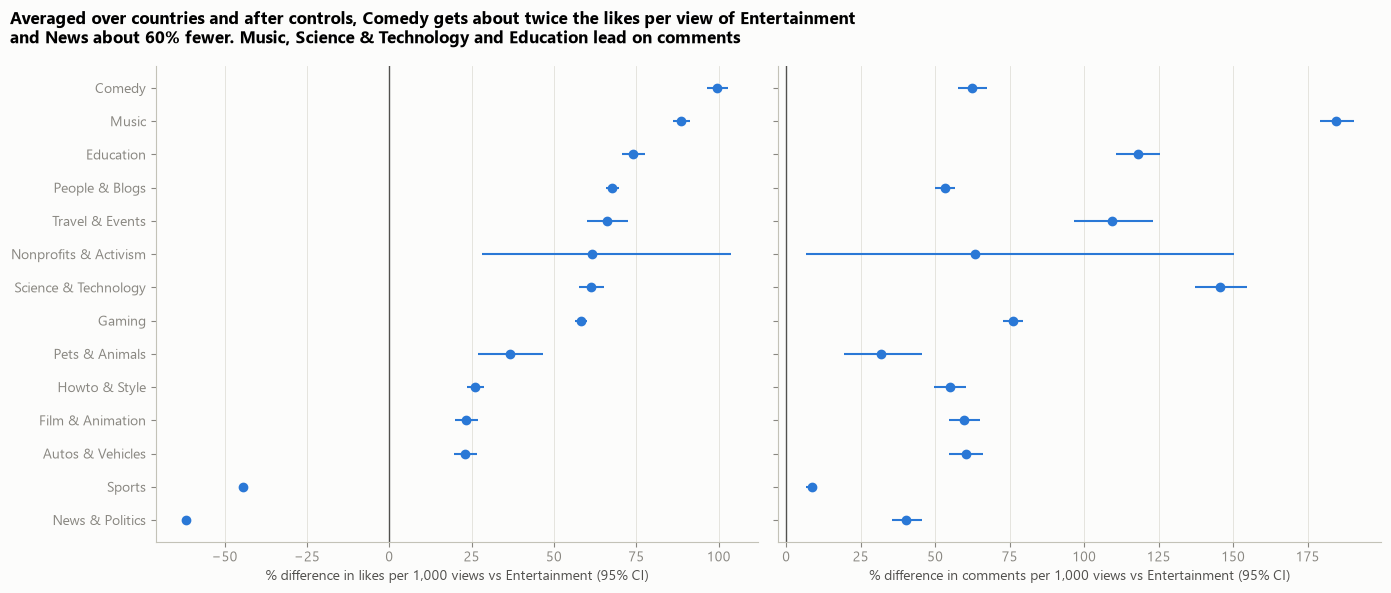

Likes per 1,000 views                         \
                             pct_difference ci_low ci_high p_value   
Comedy                                 99.5   96.3   102.7     0.0   
Music                                  88.7   86.0    91.4     0.0   
Education                              74.1   70.6    77.6     0.0   
People & Blogs                         67.6   65.6    69.6     0.0   
Travel & Events                        66.0   59.9    72.3     0.0   
Nonprofits & Activism                  61.6   28.2   103.7     0.0   
Science & Technology                   61.3   57.6    65.1     0.0   
Gaming                                 58.2   56.3    60.1     0.0   
Pets & Animals                         36.5   27.0    46.8     0.0   
Howto & Style                          26.1   23.4    28.9     0.0   
Film & Animation                       23.4   20.1    26.8     0.0   
Autos & Vehicles                       23.1   19.6    26.6     0.0   
Sports                                -44.4  -45.2   -43.7     0.0   
News & Politics                       -61.8  -62.6   -60.9     0.0   

                      Comments per 1,000 views                         
                                pct_difference ci_low ci_high p_value  
Comedy                                    62.3   57.6    67.2     0.0  
Music                                    184.7  179.0   190.4     0.0  
Education                                117.9  110.7   125.4     0.0  
People & Blogs                            53.2   50.0    56.5     0.0  
Travel & Events                          109.4   96.5   123.2     0.0  
Nonprofits & Activism                     63.5    6.7   150.5     0.0  
Science & Technology                     145.7  137.1   154.6     0.0  
Gaming                                    76.1   72.9    79.3     0.0  
Pets & Animals                            31.8   19.4    45.5     0.0  
Howto & Style                             54.8   49.5    60.3     0.0  
Film & Animation                          59.7   54.6    65.0     0.0  
Autos & Vehicles                          60.4   54.7    66.2     0.0  
Sports                                     8.5    6.5    10.4     0.0  
News & Politics                           40.3   35.4    45.4     0.0

In [8]:
effect_order = category_effects[("Likes per 1,000 views", "pct_difference")].sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, label in zip(axes, metric_labels.values()):
    effects = category_effects[label].loc[effect_order]
    ax.errorbar(effects["pct_difference"], range(len(effects)),
                xerr=[effects["pct_difference"] - effects["ci_low"], effects["ci_high"] - effects["pct_difference"]],
                fmt="o", markersize=6, color=SINGLE_SERIES_COLOR, elinewidth=1.5)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_xlabel(f"% difference in {label.lower()} vs Entertainment (95% CI)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(effect_order)), effect_order)
fig.suptitle("Averaged over countries and after controls, Comedy gets about twice the likes per view of Entertainment\n"
             "and News about 60% fewer. Music, Science & Technology and Education lead on comments",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

category_effects.loc[effect_order[::-1]].round(1)

## Finding

**Category drives likes per view, country drives comments per view, and India's likes data has a break.**

- **Measurement day matters.** Likes per 1,000 views are about 20% lower on a video's peak-views day than on its first trending day (US 54.6 vs 42.5). Because US and UK videos stay on the list longer, a peak-day comparison would understate them relative to India. All results here use the first trending day.
- **Likes: category matters most.** Within a country, category explains 20% (India) to 37% (UK) of the variation in likes per view (epsilon squared). Averaged across countries and controlling for country and audience size, Comedy gets 99.5% more likes per view than Entertainment (95% CI 96 to 103), Music 89% more, and News & Politics 62% fewer and Sports 44% fewer. News & Politics has the fewest likes per view in all three countries.
- **Rankings differ by country.** Music and Comedy lead in the US and UK (80 to 87 likes per 1,000 views). In India Gaming (97.5) and Science & Technology (92.7) lead, about double their US and UK levels, while Indian Entertainment gets 24.9, half the US level.
- **Comments: country matters most.** Indian videos get 58% (before Oct 2022) to 63% (after) fewer comments per view than US videos, after controls, and fewer in 11 of 13 categories. The UK is 8% below the US. Bigger audiences comment less per view: 10 times the views means 33% fewer comments per 1,000 views, but only 4% fewer likes.
- **India's likes data breaks on 6 October 2022.** Before it, Indian likes per view matched the US (+2.9% after controls); after it they are 29.5% lower. The category ranking inside India stays similar across the break (Spearman 0.83), and India's time to trend and time on the list do not change, so analyses 1 and 2 are not affected.

**Limitations**

- The cause of the India break is not in the data. India's engagement levels from different periods should not be compared directly.
- Only trending videos are included, so these are engagement rates of successful videos, not of all uploads.
- Likes and comments can be inflated by bots or giveaways. YouTube removes some of this, but the data cannot show how much.
- The regression's category effects are averages over countries; per-country rankings are in section 3.